# Normalization & Scaling: Visium HD (Segmented)

## Introduction

Following quality control and artifact filtering in [notebook 04](04-quality_control_VisiumHD_segmented.ipynb), we shall transform _raw transcript counts_ into _statistically comparable expression_ profiles.

In both sequencing- and imaging-based spatial transcriptomics, raw UMI counts cannot be compared directly across spatial capture units. Two segmented cells representing identical biological states can exhibit a ≥ 2-times difference in total detected transcripts due to variable array permeabilization, probe capture efficiency, flowcell sampling stochasticity, and physical cell volume differences (e.g., enlarged cribriform adenocarcinoma tumor cells versus small, spindle-shaped stromal fibroblasts).

In this notebook, we implement the standard Bioconductor normalization framework:

1. **Observation-Level Normalization:** We estimate cell-specific library **size factors** ($s_i$, scaled to a slide-wide mean of $1.0$) and apply a natural log transformation with a pseudocount to populate the `logcounts` assay slot while preserving zero counts.
2. **Feature-Level Scaling:** We center and scale selected **highly variable genes (HVGs)** to zero mean and unit variance ($Z$-score transformation), ensuring equal weighting in downstream multivariate algorithms (PCA, UMAP, and graph-based Leiden clustering).

> For a rigorous derivation of size-factor mechanics, a diagnostic guide to size-factor spatial distributions, and a comparative evaluation of advanced alternatives (such as deconvolution pooling via `scuttle::computePooledFactors()`, negative binomial regularized models via `SCTransform()`, and spatially-aware normalization methods), please consult the original SIB slide-deck and [the companion study guide](../assets/notes/05-normalization.md).

## Learning objectives

- **Compute observation-level size factors and log-normalized counts:** Implement `scuttle::logNormCounts()` on a segmented `SpatialFeatureExperiment` container to compute depth-adjusted size factors ($s_i$) and populate the variance-stabilized `logcounts` assay.
- **Diagnose spatial patterns in capture efficiency:** Inspect size factor summary statistics and project them across segmented cell geometries using `Voyager::plotSpatialFeature()` to disentangle technical capture variation from genuine histological density across CRC tumor and mucosal niches.
- **Perform gene-level feature scaling:** Standardize normalized expression profiles for key marker genes (e.g., `PIGR`, `CEACAM5`, `MUC17`, `OLFM4`) using a Z-score transformation (_mean = 0, variance = 1_) to prevent high-abundance transcripts from dominating downstream multivariate methods.
- **Evaluate spatially-aware normalization frameworks:** Contrast standard library-size normalization with spatially-aware smoothing and variance-stabilization models, critically assessing when tissue heterogeneity (e.g., invasive carcinoma vs. desmoplastic stroma) risks confounding spatial smoothing.
- **Serialize normalized spatial objects:** Export the normalized polygon-aware `SpatialFeatureExperiment` container using `alabaster.sfe::saveObject()` to establish a reproducible checkpoint for downstream dimensionality reduction and clustering.

## Environment setup

We initialize our R session by attaching the core Bioconductor packages required for segmented spatial data manipulation, size-factor normalization, and polygon visualization.

### Loading libraries

In [1]:
suppressPackageStartupMessages(suppressWarnings({
  # Core spatial container & persistence
  library(SpatialFeatureExperiment)
  library(alabaster.sfe)

  # Normalization & single-cell statistics
  library(scuttle)

  # Spatial visualization & plotting aesthetics
  library(Voyager)
  library(ggplot2)
  library(patchwork)
}))

# Enforce reproducible random number generation
set.seed(42)

### Restoring the QC-filtered Visium HD dataset

We restore the quality-controlled, segmented `SpatialFeatureExperiment` object produced at the conclusion of [notebook 04](04-quality_control_VisiumHD_segmented.ipynb).

In [ ]:
# Define path to the QC-filtered Visium HD segmented object from notebook 04
qc_data_path <- "output/sfe_visiumhd_segmented_qc-filtered"

sfe <- readObject(qc_data_path)

# Verify container architecture, geometries, and dimensions
sfe

>>> Reading SpatialExperiment

>>> Reading colgeometries



class: SpatialFeatureExperiment 
dim: 18049 33709 
metadata(1): Samples
assays(1): counts
rownames(18049): SAMD11 NOC2L ... MT-ND6 MT-CYB
rowData names(4): ID Symbol Type subsets_Mito
colnames(33709): 80404 80411 ... 189331 189341
colData names(33): Sample Barcode ... k90 artifact
reducedDimNames(1): PCA_artifacts
mainExpName: NULL
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

unit: micron
Geometries:
colGeometries: centroids (POINT), cellSeg (POLYGON), nucSeg (POLYGON) 

Graphs:
sample01: 

During quality control, we pruned 1,165 defective capture units (3.34%) using a two-tiered filter (relaxed global thresholds and `SpotSweeper` local spatial outlier detection), followed by the removal of 83 newly unexpressed genes. Our restored container contains exactly 18,049 genes across 33,709 confirmed epithelial, stromal, and immune cells.

## Size-factor log-normalization & spatial diagnostic inspection

### Mathematical framework of log-normalization

The primary objective of normalization is to correct for differences in sequencing depth and technical capture efficiency across spatial capture units without distorting biological differences. In Bioconductor, the standard framework for single-cell and spatial data is library-size log-normalization, implemented via `scuttle::logNormCounts()`.

For each gene $j$ in segmented cell $i$, the normalized log-expression value $Y_{ij}$ is computed as:

$$
Y_{ij} = \log_e \left( \frac{X_{ij}}{s_i} + 1 \right)
$$

where:

* $X_{ij}$ represents the raw transcript count from `counts(sfe)`.
* $s_i$ is the observation-specific **size factor**, defined as the cell's total UMI count ($\sum_j X_{ij}$) scaled by a slide-wide constant such that the average size factor across all valid cells equals unity ($\text{mean}(s_i) = 1.0$).
* $+1$ is the **pseudocount**, ensuring that unexpressed features ($\text{counts} = 0$) map cleanly to $\log_e(1) = 0$ while stabilizing the variance of low-abundance transcripts.

> **Computational Acceleration:** While `scuttle::logNormCounts()` is the established Bioconductor standard, the C++ accelerated implementation `scrapper::normalizeRnaCounts.se()` provides identical mathematical transformations with reduced memory footprint on ultra-dense spatial datasets.

In [3]:
# Verify existing assays before normalization
assayNames(sfe)

[1] "counts"

In [4]:
# Compute cell-specific size factors and populate the logcounts assay
sfe <- logNormCounts(sfe)

# Verify that logcounts has been registered alongside raw counts
assayNames(sfe)

Warning message in .library_size_factors(assay(x, assay.type), ...):
"'librarySizeFactors' est obsolète.
Utilisez plutôt ‘scrapper::centerSizeFactors’.
Voir help("Deprecated")"
Warning message in .local(x, ...):
"'normalizeCounts' est obsolète.
Utilisez plutôt ‘scrapper::normalizeCounts’.
Voir help("Deprecated")"


[1] "counts"    "logcounts"

The resulting normalized values are stored directly in the `logcounts` assay slot of our `SpatialFeatureExperiment` container, while the calculated size factors ($s_i$) are stored in an internal object slot accessible via `sizeFactors(sfe)`.

Because spatial plotting functions in `Voyager` query cell-level metadata directly from `colData`, we extract the size factors into a local variable (`sf`) and register them into `sfe[["sizeFactor"]]`.

In [5]:
# Extract size factors for numerical analysis and register in colData for spatial mapping
sf <- sizeFactors(sfe)
sfe[["sizeFactor"]] <- sf

In [ ]:
# Inspect available cell-level metadata attributes registered in colData
names(colData(sfe))

[1] "Sample"                        "Barcode"                      
 [3] "sample_id"                     "cell_area_um2"                
 [5] "nuc_area_um2"                  "sum"                          
 [7] "detected"                      "subsets_Mito_sum"             
 [9] "subsets_Mito_detected"         "subsets_Mito_percent"         
[11] "total"                         "qc_lib_size"                  
[13] "qc_detected"                   "qc_mito_prop"                 
[15] "sum_log"                       "sum_outliers"                 
[17] "sum_z"                         "detected_log"                 
[19] "detected_outliers"             "detected_z"                   
[21] "subsets_Mito_percent_outliers" "subsets_Mito_percent_z"       
[23] "local_outliers"                "global_outliers"              
[25] "discard"                       "subsets_Mito_percent_log"     
[27] "coords"                        "k6"                           
[29] "k18"                           "k36"                          
[31] "k60"                           "k90"                          
[33] "artifact"                      "sizeFactor"

### Quantitative evaluation of size factor distribution

Let's first evaluate the numerical behavior of our computed size factors (`sf`). In single-cell and spatial transcriptomics, size factors should adjust for library depth variations while remaining strictly positive.

In [7]:
# Tabular five-number summary
print(summary(sf))

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.1266  0.4675  0.7598  1.0000  1.2611  8.9815 


In [8]:
# Prepare data frame for visualization
df_sf <- data.frame(size_factor = sf)
sf_mean <- mean(sf)
sf_median <- median(sf)

Warning message:
"Removed 169 rows containing non-finite outside the scale range (`stat_bin()`)."
Warning message:
"Removed 2 rows containing missing values or values outside the scale range
(`geom_bar()`)."


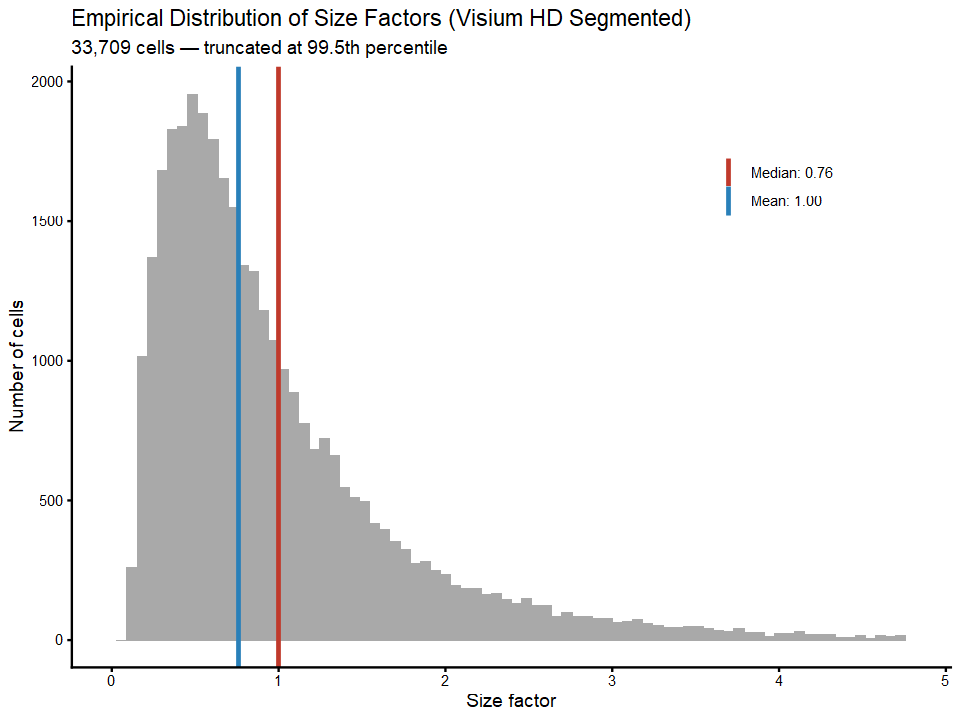

In [9]:
# Set canvas dimensions a little wider
options(repr.plot.width = 8, repr.plot.height = 6)

# Streamlined publication-style histogram
p_sf_hist <- ggplot(df_sf, aes(x = size_factor)) +
  geom_histogram(bins = 80, fill = "darkgrey") +
  geom_vline(aes(xintercept = sf_median, color = "Median"), linewidth = 1) +
  geom_vline(aes(xintercept = sf_mean, color = "Mean"), linewidth = 1) +
  scale_color_manual(
    name = NULL,
    values = c("Median" = "#2980B9", "Mean" = "#C0392B"),
    labels = c(paste0("Median: ", round(sf_median, 2)), "Mean: 1.00")
  ) +
  xlim(0, quantile(sf, 0.995)) +
  labs(
    title = "Empirical Distribution of Size Factors (Visium HD Segmented)", 
    subtitle = "33,709 cells — truncated at 99.5th percentile",
    x = "Size factor", 
    y = "Number of cells"
  ) +
  theme_classic() +
  theme(legend.position = c(0.8, 0.8))

p_sf_hist

As mathematically enforced by `scuttle::logNormCounts()`, the slide-wide arithmetic mean equals exactly 1.000 (red dashed vertical line). This calibration ensures that global transcript abundance is preserved without shifting the dataset-wide expression baseline.

Moreover, the distribution is distinctly unimodal yet asymmetric, with the median (0.76, blue dotted line) sitting substantially below the mean of 1.00:

* **The Cellular Core (IQR = 0.47–1.26):** Fifty percent of all segmented cells fall tightly within this interquartile range. These represent resting stromal fibroblasts, lamina propria lymphocytes, and tangential section cuts of mucosal cells with moderate transcript counts.
* **The High-Activity Upper Tail (Max = 8.98):** The distribution features a long upper tail extending up to a maximum size factor of 8.98. These high size factors capture transcriptionally hyperactive cribriform adenocarcinoma cells, tall columnar crypt enterocytes, and occasional multi-cell StarDist segmentation expansions. Because the arithmetic mean is sensitive to extreme positive values, this heavy upper tail pulls the mean upward relative to the median.

Interestingly, the minimum size factor is 0.13, and the distribution drops smoothly to zero without an artificial spike at the lower boundary. This confirms that our two-tiered QC filtering in [notebook 04](04-quality_control_VisiumHD_segmented.ipynb) successfully purged empty intercellular gaps, unpermeabilized spots, and damaged cellular fragments, guaranteeing that the division $X_{ij} / s_i$ remains finite and well-conditioned across all 33,709 cells.

> In single-cell RNA-seq, compositional biases driven by extreme expression of a few private marker genes are often handled by deconvolution pooling (`scuttle::computePooledFactors()`), while strong count-depth dependencies can be modeled via regularized negative binomial regression (`Seurat::SCTransform()`). As detailed in [05-normalization.md](../assets/notes/05-normalization.md), standard library-size log-normalization remains our preferred baseline for segmented spatial data because it preserves sharp histological transitions between tumor and stroma without introducing cross-boundary smoothing artifacts.

### Spatial diagnostic mapping of size factors

A critical diagnostic step in spatial transcriptomics is evaluating whether size factors reflect technical artifacts (e.g., uneven slide permeabilization, coverslip air bubbles, or reagent drying rings) or authentic tissue histology.

Having already registered our size factors into `sfe[["sizeFactor"]]`, we now project them across physical space onto the segmented cell polygons (`cellSeg`) using `Voyager::plotSpatialFeature()`. Because size factors span nearly two orders of magnitude (0.13 to 8.98), we apply a logarithmic color transformation (`trans = "log10"`) to resolve variations across both low-depth stroma and high-depth epithelial niches.

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


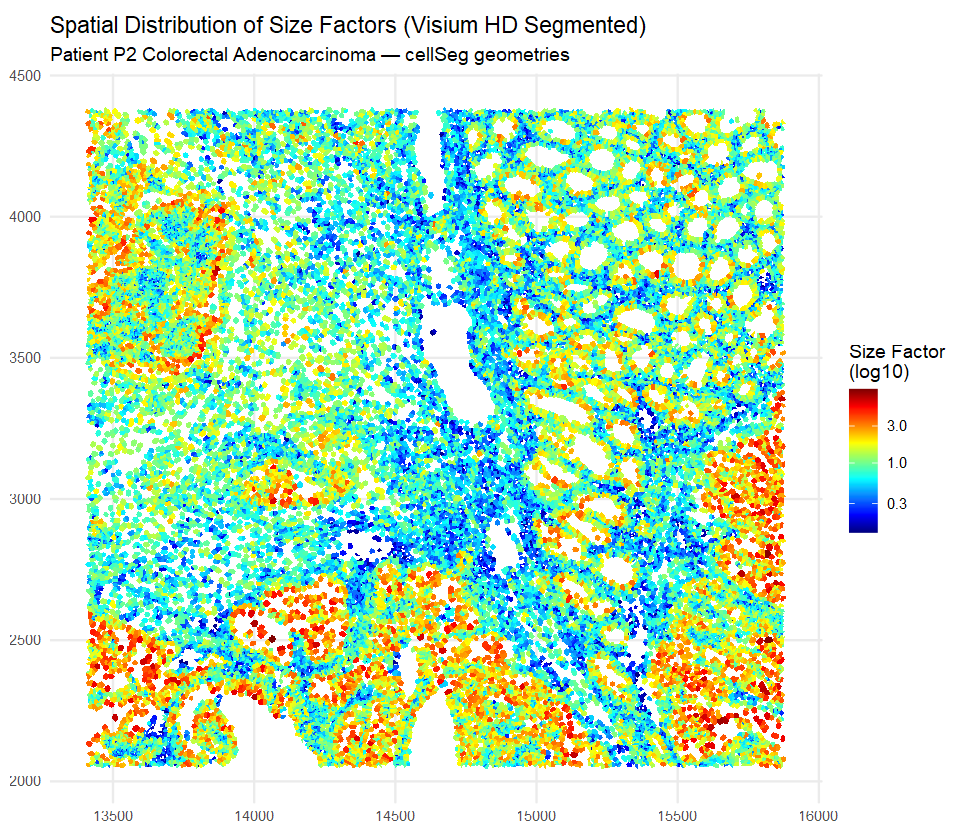

In [10]:
# Set canvas dimensions
options(repr.plot.width = 8, repr.plot.height = 7)

# Visualize size factors projected onto segmented cell polygons
p_size_factor <- plotSpatialFeature(
  sfe,
  colGeometryName = "cellSeg",
  features = "sizeFactor"
) +
  scale_fill_gradientn(
    colors = pals::jet(),
    trans = "log10",
    name = "Size Factor\n(log10)"
  ) +
  labs(
    title = "Spatial Distribution of Size Factors (Visium HD Segmented)",
    subtitle = "Patient P2 Colorectal Adenocarcinoma — cellSeg geometries"
  ) +
  theme_minimal()

p_size_factor

Size factor variation is driven by authentic tissue histology rather than technical slide artifacts (e.g., drying rings or permeabilization gradients):

* **Epithelial Niches (High Capture, $s_i \ge 1.0–3.0+$):** The malignant adenocarcinoma sheets (bottom, reaching $s_i = 8.98$, red) and normal mucosal crypts (top-right honeycomb rings, orange/yellow) show elevated size factors due to high metabolic activity and large cell volumes.
* **Stromal Niches (Low Capture, $s_i \le 0.7$):** The central desmoplastic corridor (dark blue/cyan) displays low size factors, reflecting quiescent fibroblasts and extracellular matrix with naturally sparse mRNA.

Because size factors transition abruptly at tumor–stroma boundaries, naive spatial smoothing would distort genuine biology by blurring tumor and stromal expression. Standard cell-specific log-normalization correctly rescales each cell while preserving discrete histological identities.

### Visualizing normalization effect (raw counts vs. logcounts)

We examine `PIGR` (polymeric immunoglobulin receptor), a canonical marker strictly restricted to mature mucosal epithelial cells lining the crypts of Lieberkühn. By comparing `PIGR` across physical space before and after normalization, we can evaluate whether _technical capture gradients_ are attenuated while genuine anatomical contrast is sharpened.

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


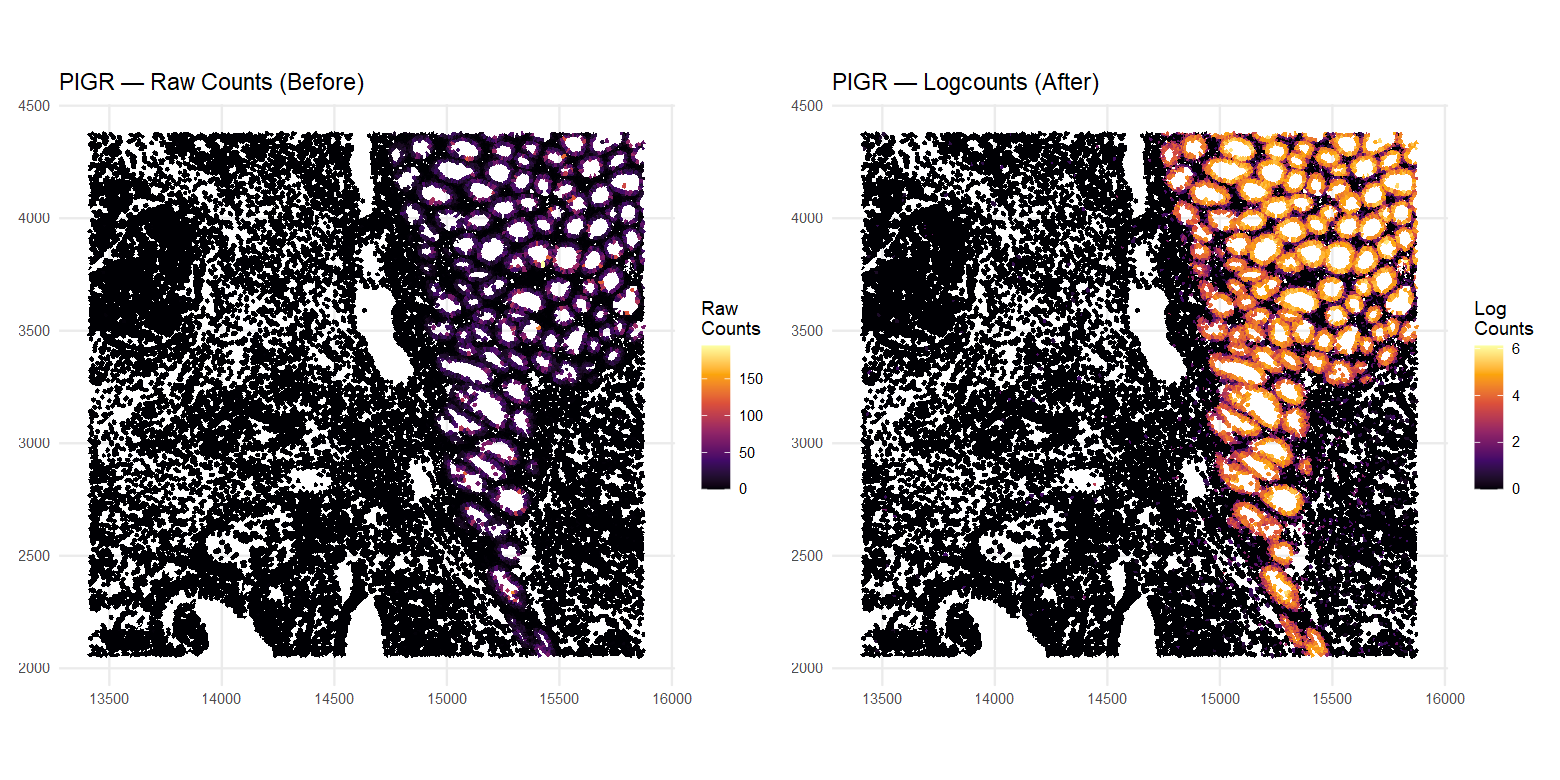

In [14]:
# Set figure canvas dimensions for side-by-side viewing
options(repr.plot.width = 13, repr.plot.height = 6.5)

# 1. Raw counts: confounded by cellular sequencing depth
p_pigr_raw <- plotSpatialFeature(
  sfe,
  features = "PIGR", 
  colGeometryName = "cellSeg", 
  exprs_values = "counts"
) +
  scale_fill_viridis_c(
    option = "inferno", 
    name = "Raw\nCounts"
  ) +
  labs(
    title = "PIGR — Raw Counts (Before)", 
  ) +
  theme_minimal()

# 2. Log-normalized counts: depth-adjusted expression
p_pigr_log <- plotSpatialFeature(
  sfe,
  features = "PIGR", 
  colGeometryName = "cellSeg", 
  exprs_values = "logcounts"
) +
  scale_fill_viridis_c(
    option = "inferno", 
    name = "Log\nCounts"
  ) +
  labs(
    title = "PIGR — Logcounts (After)", 
  ) +
  theme_minimal()

# Render side by side
p_pigr_raw | p_pigr_log

In _raw count_ space (0–150 counts), `PIGR` appears artificially faint and fragmented across the normal colonic mucosa. A small subset of high-count cells dominates the linear scale, compressing the visual dynamic range and masking the true, continuous expression of this lineage marker across the surrounding enterocytes.

_Log-normalization_ completely resolves this capture disparity (0–6 logcounts). By dividing by cell-specific size factors, the entire mucosal compartment on the right illuminates with intense signal (values 4–6), crisply delineating the honeycomb architecture of the crypts of Lieberkühn. Crucially, the adjacent desmoplastic stroma and invasive adenocarcinoma sheets remain completely negative (black), confirming that normalization unmasks authentic anatomical boundaries without leaking spurious signal into non-target tissues.

## Feature-Level scaling

### Normalization vs. scaling Golden Rule

While **normalization** operates across columns (_cells_) to remove technical sequencing depth variation, **scaling** operates across rows (_genes_) to place features on a common numerical footing. 

Highly expressed genes (such as structural cytoskeletal proteins or abundant ribosomal transcripts) naturally exhibit larger raw variances than low-abundance regulatory transcription factors or cell-type markers. Without scaling, unweighted multivariate algorithms (such as PCA, UMAP, and graph-based Leiden clustering) would be dominated almost entirely by a handful of high-abundance genes, obscuring subtle biological variation.

Feature scaling transforms log-normalized expression $Y_{ij}$ of gene $j$ in cell $i$ into a standard Z-score:

$$
Z_{ij} = \frac{Y_{ij} - \mu_j}{\sigma_j}
$$

where:

* $\mu_j$ is the mean log-normalized expression of gene $j$ across all cells ($\frac{1}{N} \sum_{i=1}^N Y_{ij}$).
* $\sigma_j$ is the standard deviation of gene $j$ across all cells.

To demonstrate row-wise scaling, we select four canonical CRC and mucosal epithelial markers:

* `PIGR`: Polymeric immunoglobulin receptor, marking mature mucosal enterocytes.
* `CEACAM5`: Carcinoembryonic antigen-related cell adhesion molecule 5, a classic colorectal adenocarcinoma biomarker.
* `MUC17`: Membrane-bound mucin protective barrier expressed by goblet and absorptive epithelial cells.
* `OLFM4`: Olfactomedin 4, marking crypt base stem cells and proliferating tumor cells.

> In single-cell and spatial transcriptomics, count matrices are stored in memory-efficient *sparse* format (`dgCMatrix`), which only stores non-zero values. Because Z-score scaling shifts zero-expression values to negative numbers ($-\mu_j / \sigma_j$), scaling all 18,049 genes would convert the matrix into a massive dense array (> 4.8 GB of RAM), risking memory exhaustion. Furthermore, scaling lowly expressed or uninformative genes artificially amplifies random technical shot noise. In standard pipelines, full scaling is performed strictly on the top 1,000–2,000 HVGs during feature selection, or on-the-fly during PCA, as we will see in the upcoming notebooks.

In [11]:
# Define canonical CRC and epithelial marker panel
marker_genes <- c("PIGR", "CEACAM5", "MUC17", "OLFM4")

# Confirm presence in our QC-filtered feature set
marker_genes <- intersect(marker_genes, rownames(sfe))

message(
  "Markers retained for scaling: ", 
  paste(marker_genes, 
  collapse = ", "))

Markers retained for scaling: PIGR, CEACAM5, MUC17, OLFM4



In [ ]:
# Define row-wise Z-score scaling function
# Note: base::scale() operates column-wise; transposing (t()) twice applies scaling across genes
scale_rows <- function(x) {
  t(base::scale(t(x)))
}

# Scale log-normalized expression values across all 33,709 cells
visium_scaled <- scale_rows(as.matrix(logcounts(sfe)[marker_genes, ]))

In [13]:
# Verify matrix dimensions and preview the first five cells
dim(visium_scaled)
round(visium_scaled[, 1:5], 3)

[1]     4 33709

,80404,80411,80412,80429,80439
PIGR,-0.485,-0.485,-0.485,-0.485,-0.485
CEACAM5,1.611,-0.825,-0.825,1.900,1.807
MUC17,-0.165,-0.165,-0.165,-0.165,-0.165
OLFM4,-0.383,-0.383,-0.383,-0.383,-0.383


The resulting scaled values ($Z_{ij}$) quantify gene expression in individual cells relative to the tissue-wide average in units of standard deviations ($\sigma_j$).

* **$Z_{ij} = 0$:** Indicates that the gene is expressed at exactly the tissue-wide average for that feature.
* **$Z_{ij} > 0$ (Positive Scaled Value):** Indicates that cell $i$ expresses gene $j$ above the slide-wide mean. The magnitude quantifies the deviation in units of standard deviations ($\sigma_j$). For example, a value of $+2.5$ denotes strong localized enrichment (e.g., intense `CEACAM5` expression in an invasive tumor gland or `PIGR` in a mucosal crypt).
* **$Z_{ij} < 0$ (Negative Scaled Value):** Indicates lower-than-average expression or complete transcriptional silence in that cell type (e.g., epithelial markers in quiescent stroma).

> Crucially, standardization must always follow library-size normalization rather than being applied directly to raw count matrices. If we scaled raw counts, cells with high capture depth, such as large, hyperactive adenocarcinoma cells, would register positive Z-scores across hundreds of unrelated genes simply because they captured more total transcripts. Performing size-factor normalization first equalizes cellular capture baselines, ensuring that positive scaled values reflect authentic biological upregulation rather than technical sequencing depth.

## Evaluating spatially-aware normalization

### The spatial normalization dilemma & the `SpaNorm` framework

In dissociated single-cell RNA-seq, total library size variations across droplets are predominantly technical. In intact tissue sections, however, library depth is deeply confounded with authentic histology: crowded, hypermetabolic compartments (such as cribriform adenocarcinoma glands or mucosal crypts) naturally yield higher transcript totals per unit area than quiescent collagenous stroma or vascular channels. Standard global normalization risks treating these authentic morphological differences as technical noise.

Spatially-aware normalization frameworks, such as `SpaNorm`, attempt to disentangle this confounding by fitting gene-wise Negative Binomial generalized additive models (NB GAMs) with 2D spatial smoothing splines across physical coordinates, as discussed in more details in the [accompanying slide-deck and notes](../assets/notes/05-normalization.md).

While statistically rigorous, full gene-wise spatially-aware modeling introduces two practical challenges. First, as noted in the [OSTA (Orchestrating Spatial Transcriptomics with Bioconductor)](https://lmweber.org/OSTA/pages/ind-normalization.html) curriculum, the computational cost is prohibitive: fitting 2D splines gene-by-gene across 33,709 cells requires hours of computation and substantial memory. Second, spatial smoothing relies on a fundamental biological assumption: that adjacent capture units share similar cellular baselines. While this assumption holds in laminar, homogeneous tissues (such as cerebral cortex), it is severely tested in colorectal adenocarcinoma, where hyperactive malignant glands directly border quiescent stroma across 10–25 µm interfaces.

### Contextualizing spatial k-NN neighborhoods across notebooks

Throughout this coursework, spatial nearest-neighbor ($k$-NN) graphs serve distinct diagnostic and analytical roles depending on the biological question, platform resolution, and algorithmic design:

* **Notebook 06 (Xenium Imaging — $k = 5$):** At subcellular single-cell resolution, we explicitly constructed an ultra-local 5-nearest-neighbor graph (`BiocNeighbors::findKNN(..., k = 5, BNPARAM = AnnoyParam())`) to identify detached cellular fragments and isolated droplets floating in acellular vascular lumens and resection margins.
* **Notebook 04 (Visium HD Quality Control — Multiscale $k = 6$ to $k = 90$):** During artifact detection with `SpotSweeper::findArtifacts()`, the algorithm builds and evaluates nested multiscale spatial graphs (`k6`, `k18`, `k36`, `k60`, `k90`) to distinguish small cellular clusters from wide contiguous slide defects (such as tissue folds or reagent drying rings). For localized cell filtering, `SpotSweeper::localOutliers()` internally evaluated each cell against its immediate $k = 36$ neighbors, storing the resulting outlier flags directly in `colData`.
* **Notebook 07 (Visium HD Normalization Simulation — $k = 36$):** Rather than fitting thousands of computationally intensive GAM splines, we simulate local spatial smoothing across immediate cellular neighborhoods. We construct a 36-nearest-neighbor graph (`BiocNeighbors::findKNN(..., k = 36)`), reusing the same $k = 36$ neighborhood (approximately 2–3 cell layers) that we calibrated in notebook 04 for `SpotSweeper::localOutliers()`, to compute the local spatial lag ($\overline{s_i^{\text{smooth}}}$).

Evaluating the resulting smoothing distortion ratio ($s_i / \overline{s_i^{\text{smooth}}}$) allows us to determine whether averaging across tissue boundaries is appropriate for this specimen.

In [ ]:
# Query the 36 spatial nearest neighbors across cell centroids (~0.15s)
knn_idx <- BiocNeighbors::findKNN(spatialCoords(sfe), k = 36)$index

# Compute spatially smoothed size factor (local neighborhood average)
sfe[["sizeFactor_smooth"]] <- rowMeans(matrix(sf[knn_idx], nrow = nrow(knn_idx)))

# Compute smoothing distortion ratio: actual size factor / smoothed size factor
sfe[["sf_ratio"]] <- sf / sfe[["sizeFactor_smooth"]]

# Inspect distribution of distortion ratios
summary(sfe[["sf_ratio"]])

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.0666  0.5975  0.8952  1.0242  1.3123  5.7127 

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


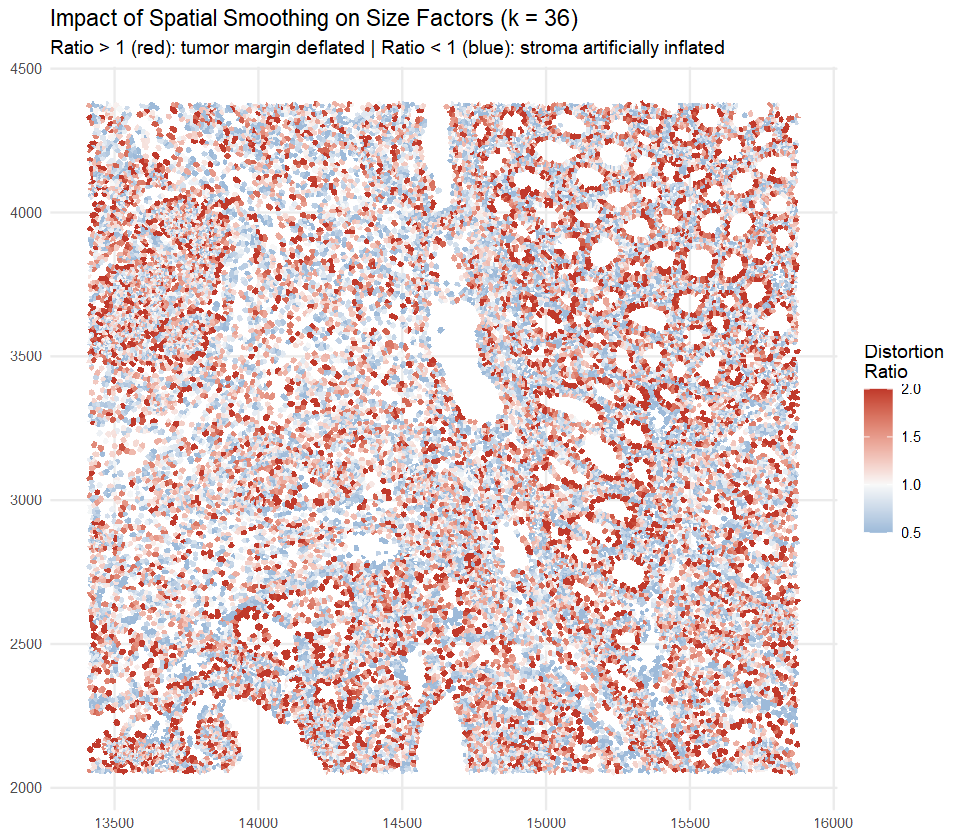

In [ ]:
# Set canvas dimensions more 1:1
options(repr.plot.width = 8, repr.plot.height = 7)

# Map the smoothing distortion across segmented cell polygons
plotSpatialFeature(
  sfe, 
  features = "sf_ratio", 
  colGeometryName = "cellSeg"
) +
  scale_fill_gradient2(
    low = "#2980B9", 
    mid = "#F8F9F9", 
    high = "#C0392B", 
    midpoint = 1.0, 
    limits = c(0.5, 2.0), 
    oob = scales::squish,  # clamps values outside [0.5, 2.0] to the nearest boundary
    name = "Distortion\nRatio"
  ) +
  labs(
    title = "Impact of Spatial Smoothing on Size Factors (k = 36)",
    subtitle = "Ratio > 1 (red): tumor margin deflated | Ratio < 1 (blue): stroma artificially inflated"
  ) +
  theme_minimal()

The empirical distribution of the distortion ratio ($s_i / \overline{s_i^{\text{smooth}}}$) spans nearly two orders of magnitude, ranging from 0.07 to 5.71. While the median sits near unity (0.90, IQR = 0.60–1.31), the spatial map reveals that this variation is strictly anatomical rather than random noise.

Across homogeneous central compartments (such as the core of the submucosal stroma), the ratio remains close to 1.0 (neutral white). However, at cellular interfaces, spatial averaging induces severe distortion. For example, along the borders of the adenocarcinoma sheets and mucosal crypts, the cell boundaries light up in dark red (ratio > 1.5 to 5.71). Because high-activity epithelial cells directly border low-count stroma, the local neighborhood average ($\overline{s_i^{\text{smooth}}}$) is dragged downward by the stromal cells. Using $\overline{s_i^{\text{smooth}}}$ would deflate their size factors by up to 5-fold, artificially inflating their normalized expression.

Conversely, quiescent fibroblasts and infiltrating lymphocytes bordering tumor glands light up in blue (ratio < 0.6 to 0.07). Their local neighborhood average is artificially inflated by high-count cancer cells, which would drastically over-deflate their normalized expression toward zero.

Because spatial size factor variations in colorectal adenocarcinoma mirror authentic tissue microarchitecture (divergent metabolic rates between neoplastic epithelium and collagenous stroma) rather than technical slide gradients, forcing spatial smoothness across tissue boundaries introduces severe cross-compartment contamination. Standard cell-specific library-size normalization (`scuttle::logNormCounts()`) correctly preserves these discrete histological boundaries.

## Finalization

### Saving the normalized SFE object

We serialize the normalized `SpatialFeatureExperiment` container to `output/sfe_visiumhd_segmented_normalized` using `alabaster.sfe::saveObject()`. Unlike standard HDF5 serializers, `alabaster.sfe` preserves all polygon geometries (`cellSeg`, `nucSeg`, `centroids`) alongside our new `logcounts` assay and cell metadata.

In [17]:
# Define the standardized output directory path for normalized data
out_path <- "output/sfe_visiumhd_segmented_normalized"

# Serialize the normalized SFE object and all spatial geometries to disk
alabaster.sfe::saveObject(sfe, out_path)

>>> Saving SpatialExperiment

>>> Saving colgeometries



In [18]:
# Verify directory creation
fs::dir_tree(out_path)

output/sfe_visiumhd_segmented_normalized
├── assays
│   ├── 0
│   │   ├── matrix.h5
│   │   └── OBJECT
│   ├── 1
│   │   ├── matrix.h5
│   │   └── OBJECT
│   └── names.json
├── colgeometries
│   ├── 0
│   │   ├── map.parquet
│   │   └── OBJECT
│   ├── 1
│   │   ├── map.parquet
│   │   └── OBJECT
│   ├── 2
│   │   ├── map.parquet
│   │   └── OBJECT
│   └── names.json
├── column_data
│   ├── basic_columns.h5
│   ├── OBJECT
│   └── other_columns
│       └── 26
│           ├── array.h5
│           └── OBJECT
├── coordinates
│   ├── array.h5
│   └── OBJECT
├── images
│   ├── 0
│   │   ├── image.tiff
│   │   └── OBJECT
│   ├── 1
│   │   ├── image.tiff
│   │   └── OBJECT
│   └── mapping.h5
├── OBJECT
├── other_data
│   ├── list_contents.json.gz
│   └── OBJECT
├── reduced_dimensions
│   ├── 0
│   │   ├── array.h5
│   │   ├── attrs
│   │   │   ├── list_contents.json.gz
│   │   │   └── OBJECT
│   │   └── OBJECT
│   └── names.json
├── row_data
│   ├── basic_columns.h5
│   └── OBJECT
└── _environm

### Clearing the Workspace

We clear the workspace and trigger garbage collection to release several gigabytes of spatial polygon geometries and count matrices from memory before opening the next module.

In [19]:
# Clear all allocated objects from the R session
rm(list = ls())

# Explicitly trigger garbage collection to reclaim system RAM
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,12911453,689.6,21034795,1123.4,21034795,1123.4
Vcells,26035396,198.7,74803717,570.8,74803717,570.8
